# Micrograd — clean notebook

In [50]:
import math
import numpy as np
import matplotlib.pyplot as plt

## 1. `Value` class — autograd engine

In [51]:
class Value:

    def __init__(self, data, _children=(), _op='', label='') -> None:
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self) -> str:
        return f"Value(data={self.data})"

    # ==================================================
    # ADDITION
    # ==================================================

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)

        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += out.grad
            other.grad += out.grad

        out._backward = _backward
        return out

    def __radd__(self, other):
        return self + other

    # ==================================================
    # NEGATION
    # ==================================================

    def __neg__(self):
        return self * -1

    # ==================================================
    # SUBTRACTION
    # ==================================================

    def __sub__(self, other):
        return self + (-other if isinstance(other, Value) else -Value(other))

    def __rsub__(self, other):
        return (-self) + other

    # ==================================================
    # MULTIPLICATION
    # ==================================================

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)

        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += out.grad * other.data
            other.grad += out.grad * self.data

        out._backward = _backward
        return out

    def __rmul__(self, other):
        return self * other

    # ==================================================
    # DIVISION
    # ==================================================

    def __truediv__(self, other):
        other = other if isinstance(other, Value) else Value(other)

        return self * (other ** -1)

    def __rtruediv__(self, other):
        return self ** -1 * other

    # ==================================================
    # POWER
    # ==================================================

    def __pow__(self, other):

        assert isinstance(other, (int, float)), \
            "Only int or float exponents are supported"

        out = Value(
            self.data ** other,
            (self,),
            f'**{other}'
        )

        def _backward(): # d/dx (x^n) = nx^(n-1)
            self.grad += (
                other * self.data ** (other - 1) * out.grad
            )

        out._backward = _backward
        return out
    
    # ==================================================
    # EXP
    # ==================================================
    
    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), 'exp')

        def _backward():
            self.grad += out.data * out.grad

        out._backward = _backward
        return out
    
    # ==================================================
    # TANH
    # ==================================================

    def tanh(self):
        x = self.data
        t = (math.exp(2 * x) - 1) / (math.exp(2 * x) + 1)

        out = Value(t, (self,), 'tanh')

        def _backward():
            self.grad += (1 - t ** 2) * out.grad

        out._backward = _backward
        return out

    # ==================================================
    # BACKWARD
    # ==================================================

    def backward(self):

        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)

                for child in v._prev:
                    build_topo(child)

                topo.append(v)

        build_topo(self)

        self.grad = 1.0

        for node in reversed(topo):
            node._backward()

    # ==================================================
    # ZERO GRADIENT
    # ==================================================

    def zero_grad(self):

        visited = set()

        def reset(v):
            if v not in visited:
                visited.add(v)
                v.grad = 0.0

                for child in v._prev:
                    reset(child)

        reset(self)


## 2. Graph visualization 

In [52]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})

    nodes, edges = trace(root)

    for n in nodes:
        uid = str(id(n))
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

## 3. Example 1

$L = ((a \cdot b) + c) \cdot f$

Example 1 grads:
  L   data= -8.0000  grad=  1.0000
  d   data=  4.0000  grad= -2.0000
  f   data= -2.0000  grad=  4.0000
  e   data= -6.0000  grad= -2.0000
  c   data= 10.0000  grad= -2.0000
  a   data=  2.0000  grad=  6.0000
  b   data= -3.0000  grad= -4.0000


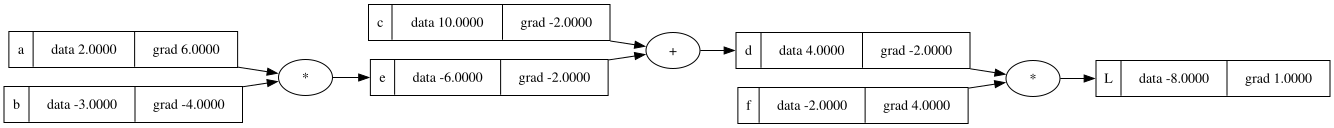

In [53]:
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a * b; e.label = 'e'
d = e + c;  d.label = 'd'
f = Value(-2.0, label='f')
L = d * f;  L.label = 'L'

L.zero_grad()
L.backward()

print("Example 1 grads:")
for node in [L, d, f, e, c, a, b]:
    print(f"  {node.label:3} data={node.data:8.4f}  grad={node.grad:8.4f}")

draw_dot(L)

In [54]:
1+a

Value(data=3.0)

## 4. Numeric check: $\frac{dL}{db}$ (finite differences)

In [55]:
def build_L(bval):
    a = Value(2.0)
    b = Value(bval)
    c = Value(10.0)
    e = a * b
    d = e + c
    f = Value(-2.0)
    L = (d * f).data
    return L

h = 0.001
numeric_dL_db = (build_L(-3.0 + h) - build_L(-3.0)) / h
print("numeric dL/db =", numeric_dL_db, " (analytic: -4.0)")

numeric dL/db = -3.9999999999995595  (analytic: -4.0)


## 5. $tanh()$ activation

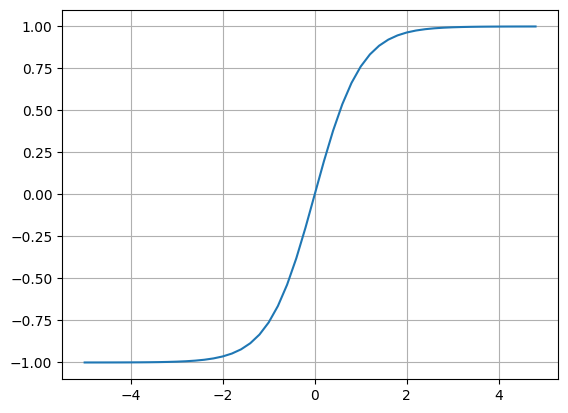

In [56]:
plt.plot(np.arange(-5, 5, 0.2), np.tanh(np.arange(-5, 5, 0.2)))
plt.grid()
plt.show()

## 6. Example 2: single neuron

$$o = \tanh(\,x_1 w_1 + x_2 w_2 + b\,)$$

Chain rule দিয়ে:

$$\frac{do}{dn} = 1 - \tanh^2(n) = 1 - o^2$$

Example 2 (neuron) grads:
  o        data=  0.7071  grad=  1.0000
  n        data=  0.8814  grad=  0.5000
  x1*w1    data= -6.0000  grad=  0.5000
  x2*w2    data=  0.0000  grad=  0.5000
  b        data=  6.8814  grad=  0.5000
  x1       data=  2.0000  grad= -1.5000
  x2       data=  0.0000  grad=  0.5000
  w1       data= -3.0000  grad=  1.0000
  w2       data=  1.0000  grad=  0.0000


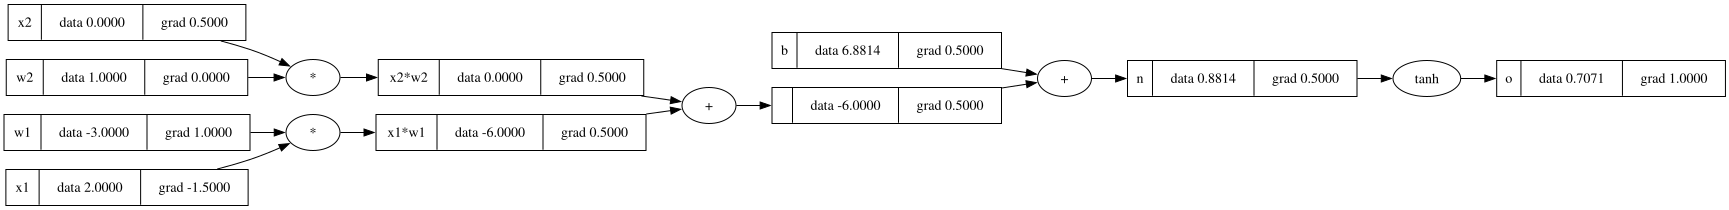

In [57]:
# inputs
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# bias
b = Value(6.8813735870195432, label='b')

x1w1 = x1 * w1; x1w1.label = 'x1*w1'
x2w2 = x2 * w2; x2w2.label = 'x2*w2'
n = x1w1 + x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'

o.zero_grad()
o.backward()

print("Example 2 (neuron) grads:")
for node in [o, n, x1w1, x2w2, b, x1, x2, w1, w2]:
    print(f"  {node.label:8} data={node.data:8.4f}  grad={node.grad:8.4f}")

draw_dot(o)

## 7. Numeric check: $\frac{do}{dw_1}$

In [58]:
def forward(w1val):
    x1 = Value(2.0)
    x2 = Value(0.0)
    w1 = Value(w1val)
    w2 = Value(1.0)
    b = Value(6.8813735870195432)
    return ((x1 * w1 + x2 * w2 + b).tanh()).data

h = 0.001
numeric_do_dw1 = (forward(-3.0 + h) - forward(-3.0)) / h
print("numeric do/dw1 =", numeric_do_dw1, " (analytic: 1.0)")

numeric do/dw1 = 0.9985864540451583  (analytic: 1.0)


Example 2 (neuron) grads:
  o        data=  0.7071  grad=  1.0000
  n        data=  0.8814  grad=  0.5000
  x1*w1    data= -6.0000  grad=  0.5000
  x2*w2    data=  0.0000  grad=  0.5000
  b        data=  6.8814  grad=  0.5000
  x1       data=  2.0000  grad= -1.5000
  x2       data=  0.0000  grad=  0.5000
  w1       data= -3.0000  grad=  1.0000
  w2       data=  1.0000  grad=  0.0000


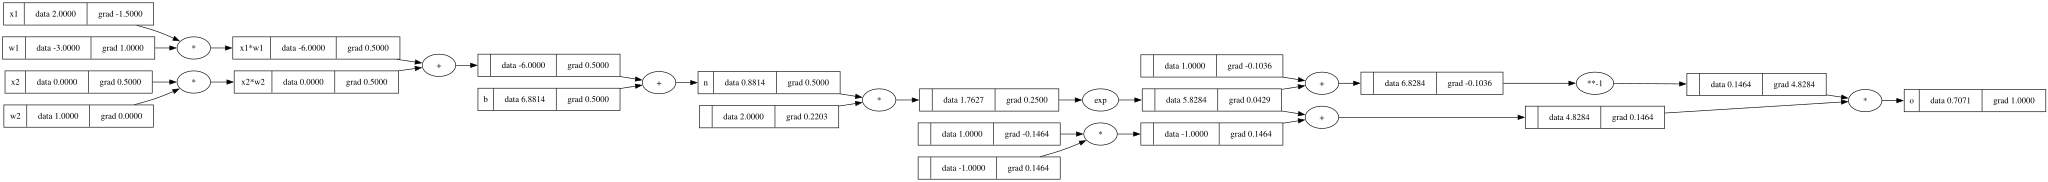

In [59]:
# inputs
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# bias
b = Value(6.8813735870195432, label='b')

x1w1 = x1 * w1; x1w1.label = 'x1*w1'
x2w2 = x2 * w2; x2w2.label = 'x2*w2'
n = x1w1 + x2w2 + b; n.label = 'n'
#=============================================
ex = (2*n).exp()
o = (ex - 1) / (ex + 1)
o.label = 'o'

o.zero_grad()
o.backward()

print("Example 2 (neuron) grads:")
for node in [o, n, x1w1, x2w2, b, x1, x2, w1, w2]:
    print(f"  {node.label:8} data={node.data:8.4f}  grad={node.grad:8.4f}")

draw_dot(o)

### Creating a `Neural Network`

In [60]:
import random
from typing import Any

class Neuron:
    
    def __init__(self, nin) -> None:
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))
        
    def __call__(self, x) -> Any:
        act = sum(wi*xi for wi, xi in zip(self.w, x)) + self.b
        out = act.tanh()
        return out
    
    def parameters(self):
        return self.w + [self.b]
    
class Layer:
    
    def __init__(self,nin, nout) -> None:
        self.neurons = [Neuron(nin) for _ in range(nout)]
        
    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs
    
    def parameters(self):
        return [p for n in self.neurons for p in n.parameters()]

class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [61]:
x = [2.0 ,3.0, -1.0]
n = MLP(3,[4,4,1])
n(x)

Value(data=0.5510359239154061)

In [62]:
len(n.parameters())

41

In [63]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]  # desired targets

In [64]:
# loss = sum((ypred[i] - ys[i]) ** 2 for i in range(len(ys)))
# loss

In [65]:
# loss.backward()

In [66]:
# n.layers[0].neurons[0].w[0].grad

In [67]:
# n.layers[0].neurons[0].w[0].data

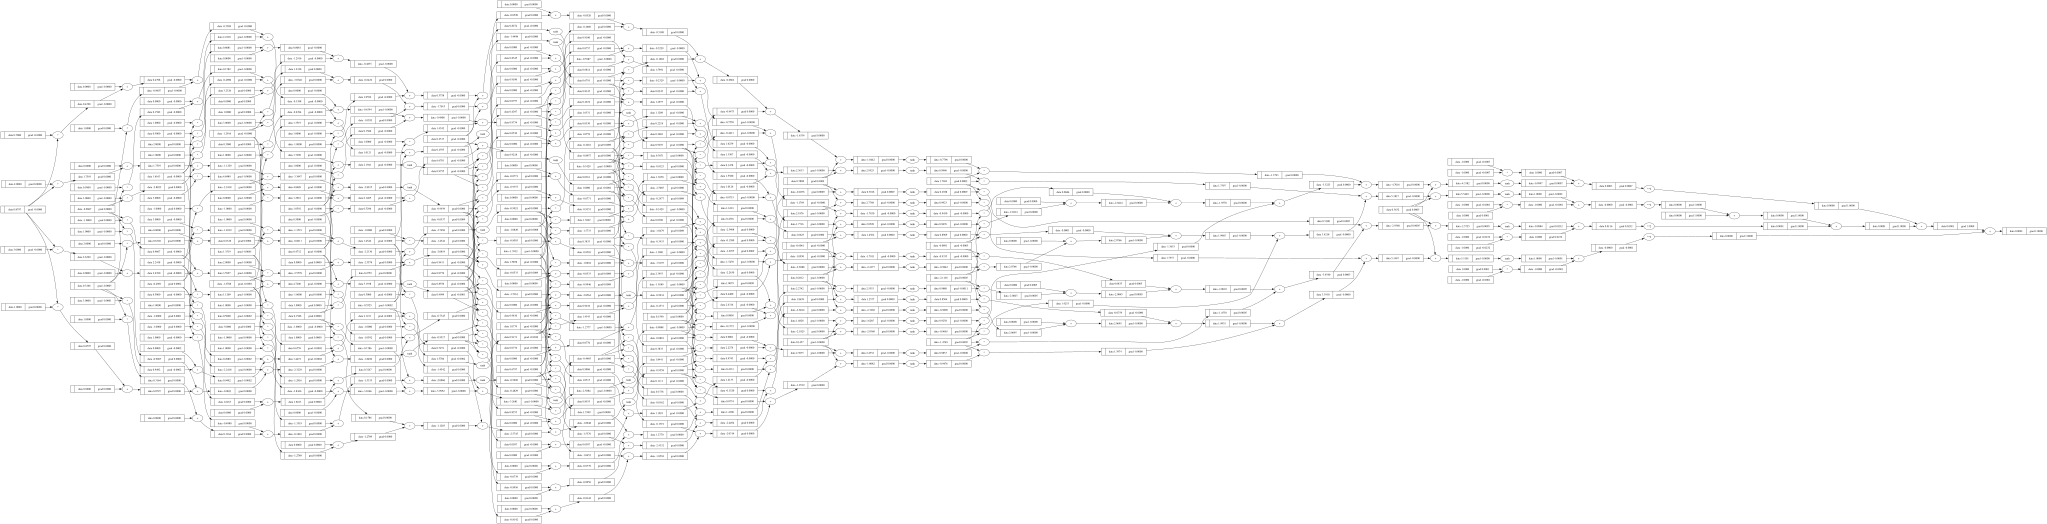

In [75]:
draw_dot(loss)

In [73]:
for epochs in range(20):
    for p in n.parameters():
        p.grad = 0.0
    # forward pass
    ypred = [n(x) for x in xs]
    loss = sum((ypred[i] - ys[i]) ** 2 for i in range(len(ys)))

    # backward pass
    loss.backward()
    
    # update settings/weights
    for p in n.parameters():
        p.data += -0.5 * p.grad
        
    print(f"epoch #{epochs} : Loss {loss.data}")

epoch #0 : Loss 0.000206869986128531
epoch #1 : Loss 0.0002012852545264381
epoch #2 : Loss 0.00019597938350166062
epoch #3 : Loss 0.0001909324521735974
epoch #4 : Loss 0.00018612637032388636
epoch #5 : Loss 0.00018154467437366922
epoch #6 : Loss 0.00017717234991853332
epoch #7 : Loss 0.00017299567688719466
epoch #8 : Loss 0.00016900209404065102
epoch #9 : Loss 0.00016518008006064273
epoch #10 : Loss 0.00016151904891343255
epoch #11 : Loss 0.00015800925753578973
epoch #12 : Loss 0.00015464172418865846
epoch #13 : Loss 0.0001514081560725945
epoch #14 : Loss 0.0001483008850063491
epoch #15 : Loss 0.00014531281014337787
epoch #16 : Loss 0.00014243734684736727
epoch #17 : Loss 0.00013966838097035047
epoch #18 : Loss 0.00013700022788139214
epoch #19 : Loss 0.0001344275956818049


In [74]:
ypred


[Value(data=0.9999694688245172),
 Value(data=-0.9884108129746277),
 Value(data=-0.999658919176612),
 Value(data=0.9999672663477632)]